## Setup 

In [1]:
###########################################################
# General setup
###########################################################

import os
import time
import tkinter as tk
from tkinter import filedialog

###########################################################
# Current directory
###########################################################

here = os.getcwd() + "/"

print("DOOM code folder:")
print(here)

###########################################################
# Local folders
###########################################################

mainpipelocation = here + "mainpipeline/"
models_directory = here + "models/"

###########################################################
# Starting image
###########################################################

imagenumber = 1

###########################################################
# Make sure processing folders exist
###########################################################

os.makedirs(mainpipelocation, exist_ok=True)

os.makedirs(mainpipelocation + "cropdump/", exist_ok=True)

os.makedirs(mainpipelocation + "cropdumpseg/", exist_ok=True)

os.makedirs(mainpipelocation + "masksdump/", exist_ok=True)

os.makedirs(mainpipelocation + "fullmaskdump/", exist_ok=True)

###########################################################
# Model paths
###########################################################

yolomodelpath = models_directory + "DOOM_bubble_model.pt"

fastaimodelpath = models_directory + "DOOM_Surface_model.pkl"


DOOM code folder:
C:\Users\bowan\Desktop\Git_hub_folder_test\Thesis_code\New_DOOM_code/


In [2]:
###########################################################
# Select image folder
###########################################################

root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)

selected_image_folder = filedialog.askdirectory(
    title="Select image folder"
)

root.destroy()

###########################################################
# Check folder was selected
###########################################################

if selected_image_folder == "":
    raise SystemExit("No image folder selected")

###########################################################
# Set data locations
###########################################################

# Convert Windows backslashes to forward slashes
rawimagesetdir = selected_image_folder.replace("\\", "/") + "/"

# Parent folder of the images folder
Data_directory = "/".join(rawimagesetdir.rstrip("/").split("/")[:-1]) + "/"

# Cycling data
spreadsheetdir = Data_directory + "Cycling_data.xlsx"

###########################################################
# Get image list
###########################################################

file_list = os.listdir(rawimagesetdir)

sorted_file_list = sorted(file_list)

totalnumberofimages = len(sorted_file_list)

###########################################################
# Function for GUI number inputs
###########################################################

def get_number_input(message, default_value):

    global user_input

    def save_input():
        global user_input
        user_input = entry.get()
        root.destroy()

    user_input = ""

    root = tk.Tk()
    root.title("DOOM setup")
    root.geometry("400x200")

    font = ("Helvetica", 24)

    label = tk.Label(
        root,
        text=message,
        font=font
    )
    label.pack()

    entry = tk.Entry(
        root,
        font=font
    )
    entry.pack()

    button = tk.Button(
        root,
        text="Next",
        command=save_input,
        font=font
    )
    button.pack()

    root.mainloop()

    if user_input == "":
        return default_value

    return int(user_input)

###########################################################
# Get starting image
###########################################################

imagenumber_start = get_number_input(
    "Input start image number:",
    0
)

###########################################################
# Get ending image
###########################################################

imagenumber_end = get_number_input(
    "Input end image number:",
    totalnumberofimages
)

###########################################################
# Get sampling frequency
###########################################################

sampling_frequency = get_number_input(
    "Process every X images:",
    1
)

###########################################################
# Check input values
###########################################################

if imagenumber_start < 0:
    imagenumber_start = 0

if imagenumber_end > totalnumberofimages:
    imagenumber_end = totalnumberofimages

if sampling_frequency < 1:
    sampling_frequency = 1

###########################################################
# Set starting image
###########################################################

imagenumber = imagenumber_start

###########################################################
# Existing mask folder
###########################################################

maskdumploaction = mainpipelocation + "fullmaskdump/"

numberoffullmasks = len(os.listdir(maskdumploaction))

###########################################################
# Calculate number of images that will be processed
###########################################################

total_images_to_process = len(
    range(
        imagenumber_start,
        imagenumber_end,
        sampling_frequency
    )
)

###########################################################
# Print setup
###########################################################

print("###########################################################")
print("DOOM setup")
print("###########################################################")
print()

print("Image folder:")
print(rawimagesetdir)

print()

print("Data directory:")
print(Data_directory)

print()

print("Cycling data:")
print(spreadsheetdir)

print()

print("Total images available:")
print(totalnumberofimages)

print()

print("Start image:")
print(imagenumber_start)

print("End image:")
print(imagenumber_end)

print("Sampling frequency:")
print(sampling_frequency)

print()

print("Images to process:")
print(total_images_to_process)

print()

print("Number of existing full masks:")
print(numberoffullmasks)

###########################################################
DOOM setup
###########################################################

Image folder:
D:/Testing_for_github/DOOM_test/images/

Data directory:
D:/Testing_for_github/DOOM_test/

Cycling data:
D:/Testing_for_github/DOOM_test/cyclingdata.xlsx

Total images available:
2500

Start image:
0
End image:
2500
Sampling frequency:
10

Images to process:
250

Number of existing full masks:
1


In [3]:
###########################################################
# Run DOOM processing loop
###########################################################

from IPython.display import clear_output

os.chdir(here)

###########################################################
# Processing setup
###########################################################

imagenumber = imagenumber_start

total_images_to_process = len(
    range(
        imagenumber_start,
        imagenumber_end,
        sampling_frequency
    )
)

images_processed = 0

processing_start_time = time.time()

###########################################################
# Processing loop
###########################################################

while imagenumber < imagenumber_end:

    ###########################################################
    # Calculate progress
    ###########################################################

    time_spent = time.time() - processing_start_time

    percentage_progress = (
        images_processed / total_images_to_process
    ) * 100

    if images_processed > 0:

        average_time_per_image = time_spent / images_processed

        images_remaining = total_images_to_process - images_processed

        ETA = average_time_per_image * images_remaining

    else:

        ETA = 0

    ###########################################################
    # Convert times to hours, minutes and seconds
    ###########################################################

    time_spent_hours = int(time_spent // 3600)
    time_spent_minutes = int((time_spent % 3600) // 60)
    time_spent_seconds = int(time_spent % 60)

    ETA_hours = int(ETA // 3600)
    ETA_minutes = int((ETA % 3600) // 60)
    ETA_seconds = int(ETA % 60)

    ###########################################################
    # Print progress
    ###########################################################

    print("###########################################################")
    print("DOOM processing progress")
    print("###########################################################")
    print()

    print(
        "Images:",
        str(images_processed + 1),
        "/",
        str(total_images_to_process)
    )

    print(
        "Progress:",
        f"{percentage_progress:.1f}%"
    )

    print(
        "Time spent:",
        f"{time_spent_hours:02d}:{time_spent_minutes:02d}:{time_spent_seconds:02d}"
    )

    if images_processed > 0:

        print(
            "ETA:",
            f"{ETA_hours:02d}:{ETA_minutes:02d}:{ETA_seconds:02d}"
        )

    else:

        print("ETA: calculating...")

    print()

    print("Current image number:", imagenumber)

    print(
        "Image range:",
        imagenumber_start,
        "to",
        imagenumber_end
    )

    print(
        "Sampling frequency:",
        sampling_frequency
    )

    print()

    ###########################################################
    # Process current image
    ###########################################################

    %run -i fullpipeslave1.ipynb

    ###########################################################
    # Update counters
    ###########################################################

    images_processed = images_processed + 1

    imagenumber = imagenumber + sampling_frequency

    ###########################################################
    # Return to DOOM directory
    ###########################################################

    os.chdir(here)

    ###########################################################
    # Clear output before next image
    ###########################################################

    clear_output(wait=True)

###########################################################
# Finished
###########################################################

total_processing_time = time.time() - processing_start_time

total_hours = int(total_processing_time // 3600)
total_minutes = int((total_processing_time % 3600) // 60)
total_seconds = int(total_processing_time % 60)

print("###########################################################")
print("DOOM processing complete")
print("###########################################################")
print()

print(
    "Images processed:",
    images_processed,
    "/",
    total_images_to_process
)

print("Progress: 100.0%")

print(
    "Total time:",
    f"{total_hours:02d}:{total_minutes:02d}:{total_seconds:02d}"
)

###########################################################
DOOM processing complete
###########################################################

Images processed: 250 / 250
Progress: 100.0%
Total time: 02:55:47


C:\Users\bowan\anaconda3\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


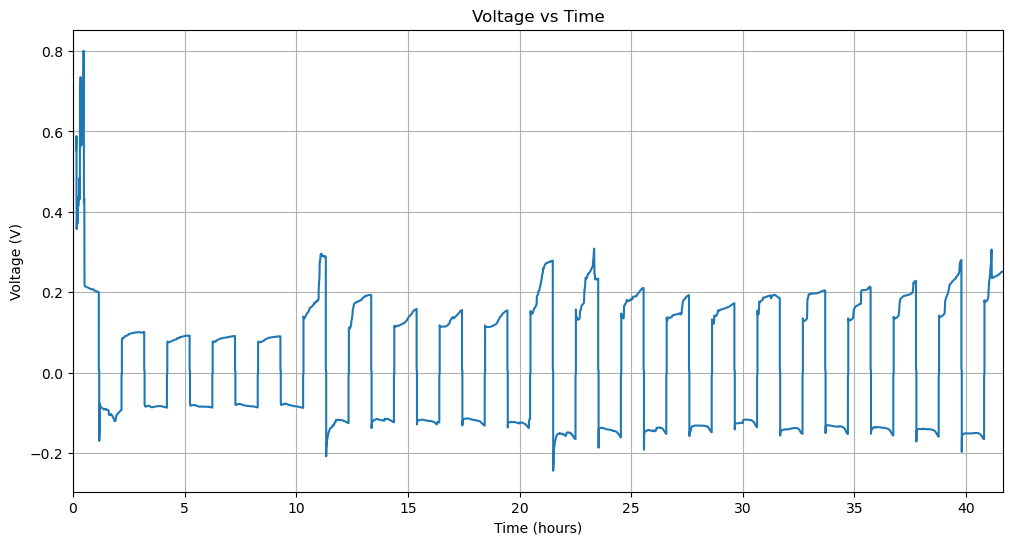

In [6]:
###########################################################
# Load cycling data
###########################################################

import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
import re

###########################################################
# Load record sheet
###########################################################

df_cycling_raw = pd.read_excel(
    spreadsheetdir,
    sheet_name="record"
)

###########################################################
# Extract cycling data
###########################################################

cycling_times = pd.to_datetime(
    df_cycling_raw["Date"]
)

Voltage = df_cycling_raw["Voltage(V)"]

Current = df_cycling_raw["Current(A)"]

###########################################################
# Get timestamp of first processed image
###########################################################

first_image_name = sorted_file_list[imagenumber_start]

date_match = re.search(
    r"\d{2}-\d{2}-\d{2}-\d{2}-\d{2}-\d{2}",
    first_image_name
)

first_image_time = datetime.strptime(
    date_match.group(),
    "%y-%m-%d-%H-%M-%S"
)

###########################################################
# Convert cycling timestamps to hours from first image
###########################################################

cycling_time_hours = (
    cycling_times - first_image_time
).dt.total_seconds() / 3600

###########################################################
# Create clean cycling dataframe
###########################################################

df_cycling = pd.DataFrame({
    "Time_hours": cycling_time_hours,
    "Voltage_V": Voltage,
    "Current_A": Current
})

###########################################################
# Restrict data to processed image time range
###########################################################

last_image_name = sorted_file_list[
    imagenumber_end - 1
]

date_match = re.search(
    r"\d{2}-\d{2}-\d{2}-\d{2}-\d{2}-\d{2}",
    last_image_name
)

last_image_time = datetime.strptime(
    date_match.group(),
    "%y-%m-%d-%H-%M-%S"
)

experiment_duration_hours = (
    last_image_time - first_image_time
).total_seconds() / 3600

df_cycling = df_cycling[
    (df_cycling["Time_hours"] >= 0) &
    (df_cycling["Time_hours"] <= experiment_duration_hours)
].reset_index(drop=True)

###########################################################
# Plot voltage vs time
###########################################################

plt.figure(figsize=(12, 6))

plt.plot(
    df_cycling["Time_hours"],
    df_cycling["Voltage_V"]
)

plt.xlabel("Time (hours)")
plt.ylabel("Voltage (V)")
plt.title("Voltage vs Time")

plt.xlim(
    0,
    experiment_duration_hours
)

plt.grid()

plt.savefig(
    Data_directory + "Voltage_vs_Time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
###########################################################
# Calculate fractional coverage of each feature
###########################################################

import cv2
import re
import numpy as np
import pandas as pd
from datetime import datetime

###########################################################
# Get processed image numbers
###########################################################

processed_image_numbers = list(range(imagenumber_start, imagenumber_end, sampling_frequency))

###########################################################
# Storage
###########################################################

coverage_data = []

###########################################################
# Process each saved mask
###########################################################

for image_number in processed_image_numbers:

    ###########################################################
    # Get image and mask names
    ###########################################################

    imagename = sorted_file_list[image_number]

    maskfilename = imagename.replace("image", "mask")

    mask_path = mainpipelocation + "fullmaskdump/" + maskfilename

    ###########################################################
    # Load mask
    ###########################################################

    mask = cv2.imread(mask_path)

    if mask is None:
        raise FileNotFoundError("Could not load mask: " + mask_path)

    ###########################################################
    # Identify each feature
    ###########################################################

    # 50 = Not Dendrites
    not_dendrite_pixels = (mask[:, :, 0] == 50) & (mask[:, :, 1] == 50) & (mask[:, :, 2] == 50)

    # 100 = Dendrites
    dendrite_pixels = (mask[:, :, 0] == 100) & (mask[:, :, 1] == 100) & (mask[:, :, 2] == 100)

    # Green = Bubbles
    bubble_pixels = (mask[:, :, 0] == 0) & (mask[:, :, 1] == 255) & (mask[:, :, 2] == 0)

    ###########################################################
    # Count pixels
    ###########################################################

    not_dendrite_count = np.sum(not_dendrite_pixels)

    dendrite_count = np.sum(dendrite_pixels)

    bubble_count = np.sum(bubble_pixels)

    total_pixels = mask.shape[0] * mask.shape[1]

    ###########################################################
    # Surface pixels excluding bubbles
    ###########################################################

    surface_pixels = not_dendrite_count + dendrite_count

    ###########################################################
    # Fraction of whole image
    ###########################################################

    not_dendrite_fraction_image = not_dendrite_count / total_pixels

    dendrite_fraction_image = dendrite_count / total_pixels

    bubble_fraction_image = bubble_count / total_pixels

    ###########################################################
    # Fraction of analysed surface
    # Bubbles excluded
    ###########################################################

    if surface_pixels > 0:

        not_dendrite_fraction_surface = not_dendrite_count / surface_pixels

        dendrite_fraction_surface = dendrite_count / surface_pixels

    else:

        not_dendrite_fraction_surface = np.nan

        dendrite_fraction_surface = np.nan

    ###########################################################
    # Get image time
    ###########################################################

    date_match = re.search(r"\d{2}-\d{2}-\d{2}-\d{2}-\d{2}-\d{2}", imagename)

    if date_match is None:
        raise ValueError("Could not find timestamp in image name: " + imagename)

    image_time = datetime.strptime(date_match.group(), "%y-%m-%d-%H-%M-%S")

    time_hours = (image_time - first_image_time).total_seconds() / 3600

    ###########################################################
    # Store results
    ###########################################################

    coverage_data.append({
        "Image_number": image_number,
        "Image_name": imagename,
        "Time_hours": time_hours,

        "Not_Dendrites_pixels": not_dendrite_count,
        "Dendrites_pixels": dendrite_count,
        "Bubbles_pixels": bubble_count,

        "Not_Dendrites_fraction_image": not_dendrite_fraction_image,
        "Dendrites_fraction_image": dendrite_fraction_image,
        "Bubbles_fraction_image": bubble_fraction_image,

        "Not_Dendrites_fraction_surface": not_dendrite_fraction_surface,
        "Dendrites_fraction_surface": dendrite_fraction_surface
    })

###########################################################
# Convert to dataframe
###########################################################

df_coverage = pd.DataFrame(coverage_data)

###########################################################
# Save coverage data
###########################################################

df_coverage.to_csv(Data_directory + "DOOM_fractional_coverage.csv", index=False)

###########################################################
# Display dataframe
###########################################################

display(df_coverage)

,Image_number,Image_name,Time_hours,Not_Dendrites_pixels,Dendrites_pixels,Bubbles_pixels,Not_Dendrites_fraction_image,Dendrites_fraction_image,Bubbles_fraction_image,Not_Dendrites_fraction_surface,Dendrites_fraction_surface
0,0,bbc_12_823-11-06-16-46-58.png,0.000000,8228289,66111,0,0.992029,0.007971,0.000000,0.992029,0.007971
1,10,bbc_12_823-11-06-16-56-58.png,0.166667,8234678,59722,0,0.992800,0.007200,0.000000,0.992800,0.007200
2,20,bbc_12_823-11-06-17-06-58.png,0.333333,8128767,165633,0,0.980031,0.019969,0.000000,0.980031,0.019969
3,30,bbc_12_823-11-06-17-16-58.png,0.500000,7976162,318238,0,0.961632,0.038368,0.000000,0.961632,0.038368
4,40,bbc_12_823-11-06-17-26-58.png,0.666667,7736115,558285,0,0.932691,0.067309,0.000000,0.932691,0.067309
...,...,...,...,...,...,...,...,...,...,...,...
245,2450,bbc_12_823-11-08-09-37-09.png,40.836389,5199078,2728926,366396,0.626818,0.329008,0.044174,0.655787,0.344213
246,2460,bbc_12_823-11-08-09-47-09.png,41.003056,4969724,2929345,395331,0.599166,0.353171,0.047662,0.629153,0.370847
247,2470,bbc_12_823-11-08-09-57-09.png,41.169722,4751544,3052907,489949,0.572862,0.368068,0.059070,0.608825,0.391175
248,2480,bbc_12_823-11-08-10-07-09.png,41.336389,4338818,3463734,491848,0.523102,0.417599,0.059299,0.556077,0.443923


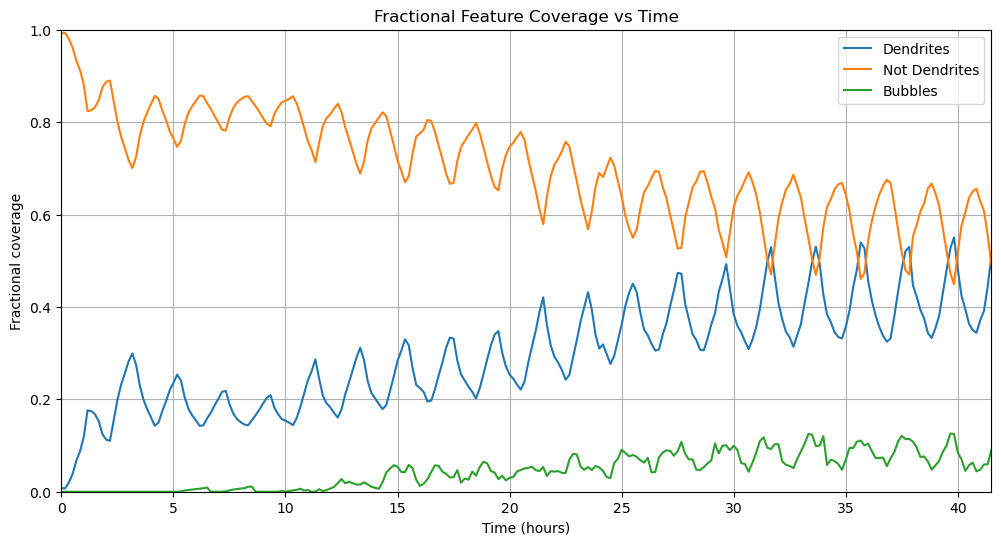

In [12]:
###########################################################
# Plot fractional feature coverage
###########################################################

plt.figure(figsize=(12, 6))

###########################################################
# Dendrite coverage
###########################################################

plt.plot(
    df_coverage["Time_hours"],
    df_coverage["Dendrites_fraction_surface"],
    label="Dendrites"
)

###########################################################
# Not dendrite coverage
###########################################################

plt.plot(
    df_coverage["Time_hours"],
    df_coverage["Not_Dendrites_fraction_surface"],
    label="Not Dendrites"
)

###########################################################
# Bubble coverage
###########################################################

plt.plot(
    df_coverage["Time_hours"],
    df_coverage["Bubbles_fraction_image"],
    label="Bubbles"
)

###########################################################
# Plot formatting
###########################################################

plt.xlabel( "Time (hours)")

plt.ylabel("Fractional coverage")

plt.title("Fractional Feature Coverage vs Time")

plt.xlim(df_coverage["Time_hours"].min(),df_coverage["Time_hours"].max())

plt.ylim( 0, 1)

plt.legend()

plt.grid()

###########################################################
# Save plot
###########################################################

plt.savefig(
    Data_directory + "DOOM_fractional_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
###########################################################
# Generate DOOM dashboard frames
###########################################################

import os
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import clear_output

###########################################################
# Dashboard output folders
###########################################################

dashboard_folder = Data_directory + "DOOM_dashboard_frames/"
dashboard_video_folder = Data_directory + "DOOM_dashboard_video/"

###########################################################
# Reset output folders
###########################################################

if os.path.exists(dashboard_folder):
    shutil.rmtree(dashboard_folder)

os.makedirs(dashboard_folder, exist_ok=True)
os.makedirs(dashboard_video_folder, exist_ok=True)

###########################################################
# Common plot limits
###########################################################

coverage_y_max = max(
    df_coverage["Not_Dendrites_fraction_surface"].max(),
    df_coverage["Dendrites_fraction_surface"].max(),
    df_coverage["Bubbles_fraction_image"].max()
)

voltage_y_min = df_cycling["Voltage_V"].min()
voltage_y_max = df_cycling["Voltage_V"].max()

time_x_min = df_coverage["Time_hours"].min()
time_x_max = df_coverage["Time_hours"].max()

###########################################################
# Generate frames
###########################################################

frame_number = 0

while frame_number < len(df_coverage):

    ###########################################################
    # Current row
    ###########################################################

    current_row = df_coverage.iloc[frame_number]

    current_image_number = int(current_row["Image_number"])
    current_image_name = current_row["Image_name"]
    current_time = current_row["Time_hours"]

    ###########################################################
    # Load original image
    ###########################################################

    original_image_path = rawimagesetdir + current_image_name
    original_image = Image.open(original_image_path)

    ###########################################################
    # Load DOOM mask
    ###########################################################

    mask_name = current_image_name.replace("image", "mask")
    mask_path = mainpipelocation + "fullmaskdump/" + mask_name
    mask_image = Image.open(mask_path)

    ###########################################################
    # Create dashboard figure
    ###########################################################

    fig, axes = plt.subplots(2, 2, figsize=(16, 9))

    ###########################################################
    # Top left: original image
    ###########################################################

    axes[0, 0].imshow(original_image)
    axes[0, 0].set_title("Original image")
    axes[0, 0].axis("off")

    ###########################################################
    # Bottom left: DOOM mask
    ###########################################################

    axes[1, 0].imshow(mask_image)
    axes[1, 0].set_title("DOOM mask")
    axes[1, 0].axis("off")

    ###########################################################
    # Top right: feature coverage plot
    ###########################################################

    axes[0, 1].plot(
        df_coverage["Time_hours"],
        df_coverage["Not_Dendrites_fraction_surface"],
        label="Not Dendrites"
    )

    axes[0, 1].plot(
        df_coverage["Time_hours"],
        df_coverage["Dendrites_fraction_surface"],
        label="Dendrites"
    )

    axes[0, 1].plot(
        df_coverage["Time_hours"],
        df_coverage["Bubbles_fraction_image"],
        label="Bubbles"
    )

    axes[0, 1].axvline(
        current_time,
        color="red",
        linestyle="--",
        linewidth=2
    )

    axes[0, 1].set_xlim(time_x_min, time_x_max)
    axes[0, 1].set_ylim(0, coverage_y_max * 1.05)
    axes[0, 1].set_xlabel("Time (hours)")
    axes[0, 1].set_ylabel("Fractional coverage")
    axes[0, 1].set_title("Feature coverage")
    axes[0, 1].legend()
    axes[0, 1].grid()

    ###########################################################
    # Bottom right: voltage plot
    ###########################################################

    axes[1, 1].plot(
        df_cycling["Time_hours"],
        df_cycling["Voltage_V"]
    )

    axes[1, 1].axvline(
        current_time,
        color="red",
        linestyle="--",
        linewidth=2
    )

    axes[1, 1].set_xlim(time_x_min, time_x_max)
    axes[1, 1].set_ylim(voltage_y_min, voltage_y_max)
    axes[1, 1].set_xlabel("Time (hours)")
    axes[1, 1].set_ylabel("Voltage (V)")
    axes[1, 1].set_title("Voltage vs time")
    axes[1, 1].grid()

    ###########################################################
    # Figure title
    ###########################################################

    fig.suptitle(
        "DOOM dashboard | "
        + "Frame "
        + str(frame_number + 1)
        + " / "
        + str(len(df_coverage))
        + " | "
        + "Image "
        + str(current_image_number)
        + " | "
        + f"{current_time:.2f} hours",
        fontsize=16
    )

    plt.tight_layout()

    ###########################################################
    # Save frame
    ###########################################################

    frame_name = "dashboard_" + str(frame_number).zfill(5) + ".png"
    frame_path = dashboard_folder + frame_name

    plt.savefig(
        frame_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close()

    ###########################################################
    # Progress print
    ###########################################################

    clear_output(wait=True)

    print("###########################################################")
    print("Generating dashboard frames")
    print("###########################################################")
    print()
    print("Frame:", frame_number + 1, "/", len(df_coverage))
    print("Progress:", f"{((frame_number + 1) / len(df_coverage)) * 100:.1f}%")
    print("Current image:", current_image_name)

    frame_number = frame_number + 1

###########################################################
# Finished
###########################################################

clear_output(wait=True)

print("###########################################################")
print("Dashboard frame generation complete")
print("###########################################################")
print()
print("Frames saved in:")
print(dashboard_folder)

###########################################################
Dashboard frame generation complete
###########################################################

Frames saved in:
D:/Testing_for_github/DOOM_test/DOOM_dashboard_frames/


In [15]:
###########################################################
# Turn dashboard frames into video
###########################################################

import cv2
from IPython.display import clear_output

###########################################################
# Video settings
###########################################################

dashboard_video_path = dashboard_video_folder + "DOOM_dashboard.mp4"
dashboard_fps = 10

###########################################################
# Get frame list
###########################################################

frame_list = os.listdir(dashboard_folder)
frame_list = sorted(frame_list)

if len(frame_list) == 0:
    raise ValueError("No dashboard frames found")

###########################################################
# Get frame size
###########################################################

first_frame_path = dashboard_folder + frame_list[0]
first_frame = cv2.imread(first_frame_path)

frame_height = first_frame.shape[0]
frame_width = first_frame.shape[1]

###########################################################
# Create video writer
###########################################################

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

video_writer = cv2.VideoWriter(
    dashboard_video_path,
    fourcc,
    dashboard_fps,
    (frame_width, frame_height)
)

###########################################################
# Write frames to video
###########################################################

frame_number = 0

while frame_number < len(frame_list):

    frame_path = dashboard_folder + frame_list[frame_number]
    frame = cv2.imread(frame_path)

    video_writer.write(frame)

    clear_output(wait=True)

    print("###########################################################")
    print("Generating dashboard video")
    print("###########################################################")
    print()
    print("Frame:", frame_number + 1, "/", len(frame_list))
    print("Progress:", f"{((frame_number + 1) / len(frame_list)) * 100:.1f}%")

    frame_number = frame_number + 1

###########################################################
# Finish
###########################################################

video_writer.release()
cv2.destroyAllWindows()

clear_output(wait=True)

print("###########################################################")
print("Dashboard video complete")
print("###########################################################")
print()
print("Video saved as:")
print(dashboard_video_path)

###########################################################
Dashboard video complete
###########################################################

Video saved as:
D:/Testing_for_github/DOOM_test/DOOM_dashboard_video/DOOM_dashboard.mp4
